# EDA

## Carga de datos y distribución de clases

Total de imágenes: 27000
Tamaño de cada imagen: torch.Size([3, 64, 64]) (Canales x Alto x Ancho)

Imágenes por clase:
AnnualCrop: 3000
Forest: 3000
HerbaceousVegetation: 3000
Highway: 2500
Industrial: 2500
Pasture: 2000
PermanentCrop: 2500
Residential: 3000
River: 2500
SeaLake: 3000


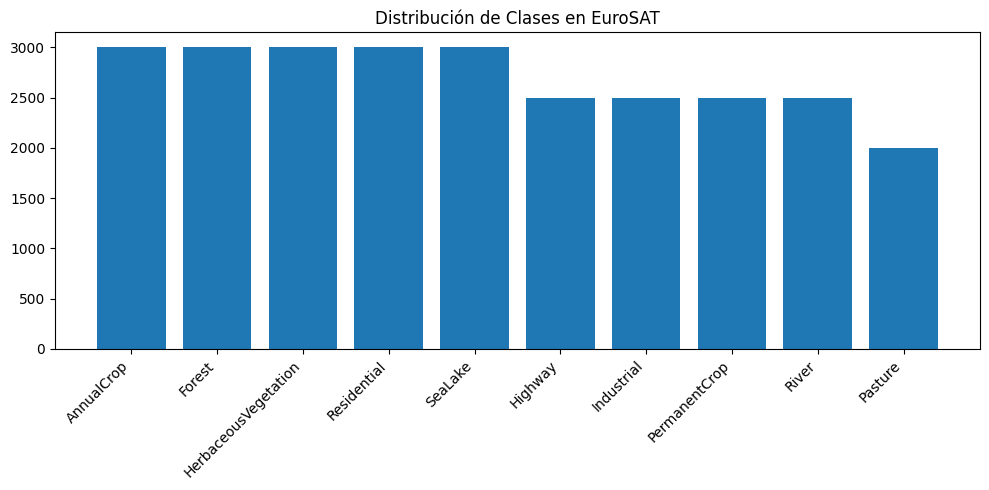

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

dataset = torchvision.datasets.EuroSAT(root='./data', download=True, transform=transforms.ToTensor())

print(f"Total de imágenes: {len(dataset)}")
sample_img, sample_label = dataset[0]
print(f"Tamaño de cada imagen: {sample_img.shape} (Canales x Alto x Ancho)")

class_names = dataset.classes
labels = [label for _, label in dataset]
class_counts = Counter(labels)

sorted_counts = class_counts.most_common()

print("\nImágenes por clase:")
for class_idx, count in class_counts.items():
    print(f"{class_names[class_idx]}: {count}")

sorted_class_names = [class_names[idx] for idx, count in sorted_counts]
sorted_values = [count for idx, count in sorted_counts]

plt.figure(figsize=(10, 5))
plt.bar(sorted_class_names, sorted_values)
plt.xticks(rotation=45, ha='right')
plt.title("Distribución de Clases en EuroSAT")
plt.tight_layout()
plt.show()

## Outliers

Suelen ser imágenes con excesiva nubosidad, errores del sensor (bandas negras) o artefactos atmosféricos. Antes de extraer características más complejas,analizamos el brillo medio (intensidad) de cada parche.

Primero usamos Rango Intercuartílico:

Límites IQR calculados: < 0.035 y > 0.701
Detectados: 0 oscuros, 320 brillantes


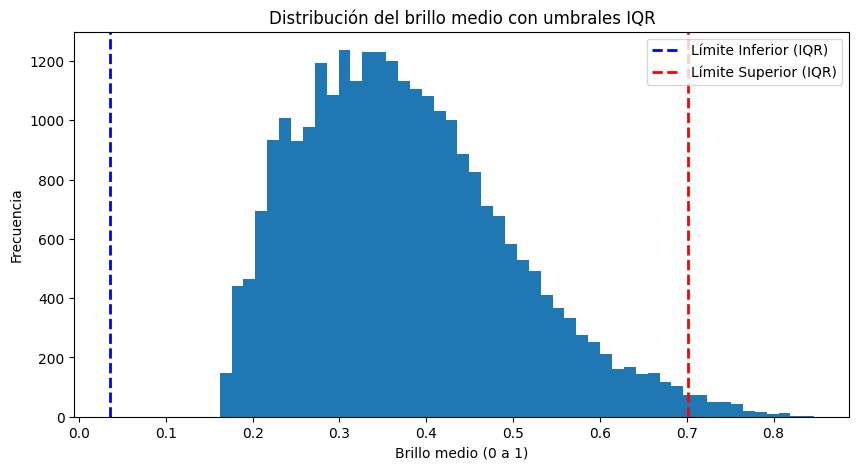

No se detectaron outliers oscuros para visualizar.


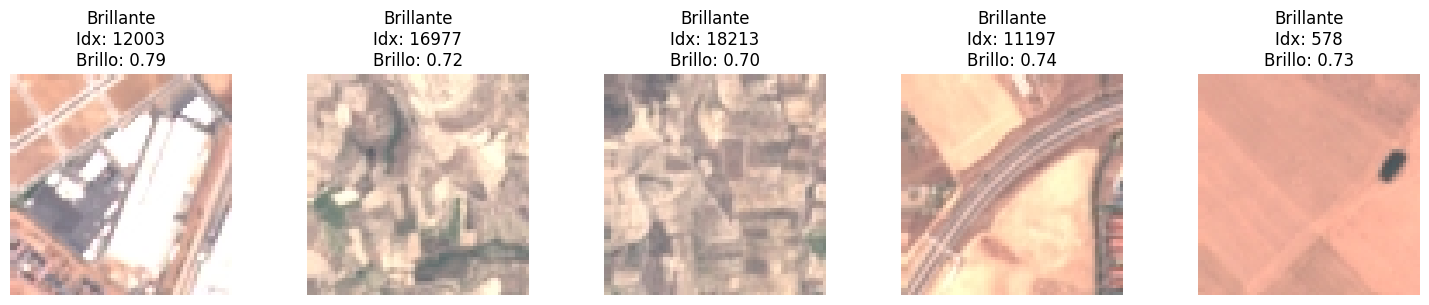

In [ ]:
mean_brightness = []
for img, _ in dataset:
    mean_brightness.append(img.mean().item())
mean_brightness = np.array(mean_brightness)

# Cálculo de límites mediante Rango Intercuartílico (IQR)
q1 = np.percentile(mean_brightness, 25)
q3 = np.percentile(mean_brightness, 75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

real_dark_outliers = np.where(mean_brightness < lower_bound)[0]
real_bright_outliers = np.where(mean_brightness > upper_bound)[0]

print(f"Límites IQR calculados: < {lower_bound:.3f} y > {upper_bound:.3f}")
print(f"Detectados: {len(real_dark_outliers)} oscuros, {len(real_bright_outliers)} brillantes")

plt.figure(figsize=(10, 5))
plt.hist(mean_brightness, bins=50)
plt.axvline(lower_bound, color='blue', linestyle='dashed', linewidth=2, label='Límite Inferior (IQR)')
plt.axvline(upper_bound, color='red', linestyle='dashed', linewidth=2, label='Límite Superior (IQR)')
plt.title("Distribución del brillo medio con umbrales IQR")
plt.xlabel("Brillo medio (0 a 1)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

def plot_outlier_samples(indices, title_prefix):
    if len(indices) == 0:
        print(f"No se detectaron outliers {title_prefix.lower()}s para visualizar.")
        return

    num_samples = min(5, len(indices))
    sample_indices = np.random.choice(indices, num_samples, replace=False)

    fig, axes = plt.subplots(1, num_samples, figsize=(15, 3))
    if num_samples == 1: axes = [axes]

    for i, idx in enumerate(sample_indices):
        img, _ = dataset[idx]

        # Adaptación para tensores de PyTorch (C, H, W) -> (H, W, C)
        if hasattr(img, 'permute'):
            img = img.permute(1, 2, 0).numpy()

        axes[i].imshow(img, cmap='gray' if len(img.shape) == 2 else None)
        axes[i].set_title(f"{title_prefix}\nIdx: {idx}\nBrillo: {mean_brightness[idx]:.2f}")
        axes[i].axis("off")

    plt.tight_layout()
    plt.show()

plot_outlier_samples(real_dark_outliers, "Oscuro")
plot_outlier_samples(real_bright_outliers, "Brillante")

Probamos también con umbrales absolutos:

Umbrales absolutos definidos: < 0.15 y > 0.8
Detectados: 0 oscuros, 21 brillantes


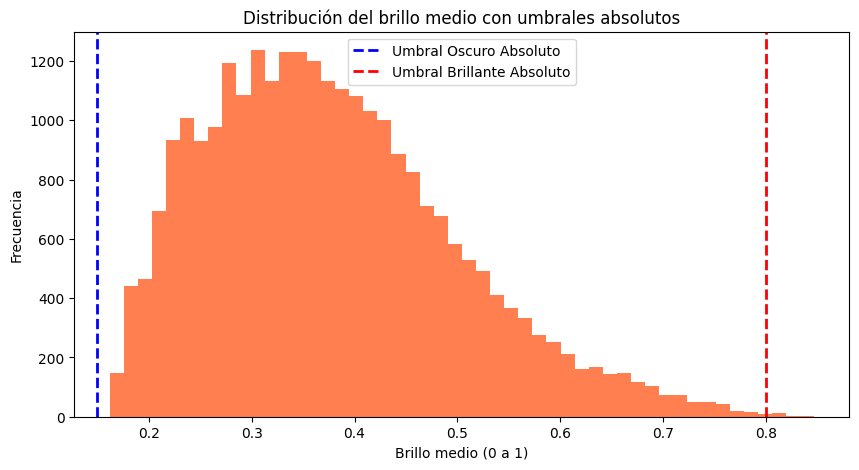

No se detectaron outliers oscuro absolutos para visualizar.


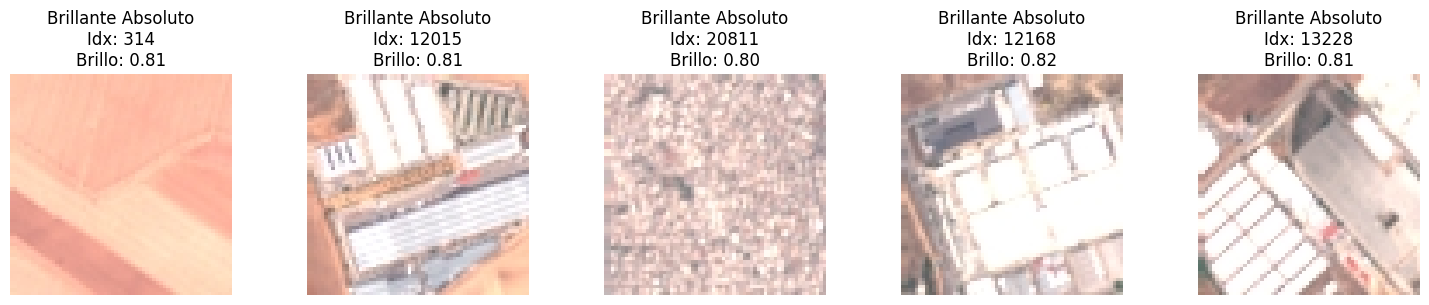

In [ ]:
umbral_oscuro = 0.15
umbral_brillante = 0.80

abs_dark_outliers = np.where(mean_brightness < umbral_oscuro)[0]
abs_bright_outliers = np.where(mean_brightness > umbral_brillante)[0]

print(f"Umbrales absolutos definidos: < {umbral_oscuro} y > {umbral_brillante}")
print(f"Detectados: {len(abs_dark_outliers)} oscuros, {len(abs_bright_outliers)} brillantes")

plt.figure(figsize=(10, 5))
plt.hist(mean_brightness, bins=50, color='coral')
plt.axvline(umbral_oscuro, color='blue', linestyle='dashed', linewidth=2, label='Umbral Oscuro Absoluto')
plt.axvline(umbral_brillante, color='red', linestyle='dashed', linewidth=2, label='Umbral Brillante Absoluto')
plt.title("Distribución del brillo medio con umbrales absolutos")
plt.xlabel("Brillo medio (0 a 1)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

plot_outlier_samples(abs_dark_outliers, "Oscuro Absoluto")
plot_outlier_samples(abs_bright_outliers, "Brillante Absoluto")

## Exploración de Espacios de Color (RGB vs HSV vs Lab)

Sentinel-2 capta bandas espectrales que interactúan distinto con los materiales.

RGB: Bueno para identificar estructuras creadas por el hombre (tejados, asfalto).

HSV: Excelente para discriminar vegetación. El canal de Matiz (Hue) separará fácilmente los bosques (Forest) de los cultivos anuales (AnnualCrop).

Lab: Muy robusto a los cambios de iluminación y sombras topográficas. Útil para masas de agua (SeaLake, River).

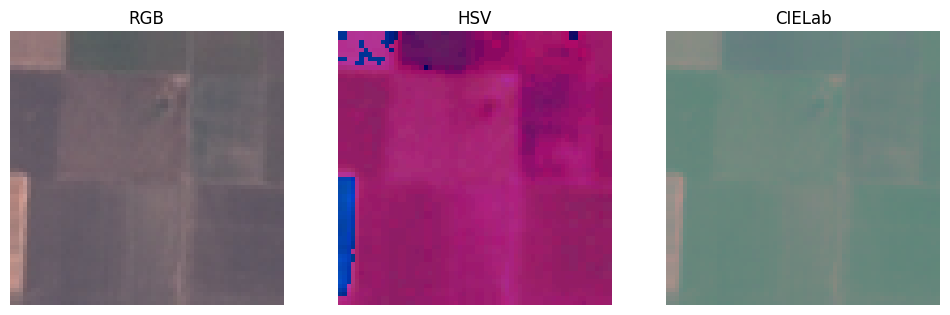

In [ ]:
import cv2

def plot_color_spaces(image_tensor):
    # Convertir tensor (C, H, W) a numpy array (H, W, C) en rango 0-255
    img_np = (image_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)

    # Convertir a HSV y LAB
    hsv_img = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)
    lab_img = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)

    fig, axs = plt.subplots(1, 3, figsize=(12, 4))
    axs[0].imshow(img_np)
    axs[0].set_title("RGB")
    axs[1].imshow(hsv_img)
    axs[1].set_title("HSV")
    axs[2].imshow(lab_img)
    axs[2].set_title("CIELab")

    for ax in axs:
        ax.axis('off')
    plt.show()

plot_color_spaces(dataset[0][0])

## Características Espectrales:

Extraemos media, desviación estándar, sesgo y curtosis para cada uno de los 3 canales en los 3 espacios de color. Esto generará un vector de 36 características por imagen (4 métricas × 3 canales × 3 espacios).

In [ ]:
import pandas as pd
from scipy.stats import skew, kurtosis
from tqdm import tqdm

def get_channel_stats(channel_data):
    flat_data = channel_data.flatten()
    return [
        np.mean(flat_data),
        np.std(flat_data),
        skew(flat_data),
        kurtosis(flat_data)
    ]

def extract_features(img_tensor):
    img_rgb = (img_tensor.permute(1, 2, 0).numpy() * 255).astype(np.uint8)
    img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    img_lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)

    features = []
    for img_space in [img_rgb, img_hsv, img_lab]:
        for i in range(3): # Canales 0, 1, 2
            features.extend(get_channel_stats(img_space[:, :, i]))
    return features

all_features = []
all_labels = []

print("Extrayendo características espectrales...")
for img, label in tqdm(dataset):
    feats = extract_features(img)
    all_features.append(feats)
    all_labels.append(label)

col_names = []
for space in ['RGB', 'HSV', 'LAB']:
    for channel in ['C1', 'C2', 'C3']:
        for stat in ['mean', 'std', 'skew', 'kurtosis']:
            col_names.append(f"{space}_{channel}_{stat}")

df_features = pd.DataFrame(all_features, columns=col_names)
df_features['label_idx'] = all_labels
df_features['label_name'] = df_features['label_idx'].apply(lambda x: dataset.classes[x])

print(f"\nExtracción completada. Dimensiones del DataFrame: {df_features.shape}")
# Guardar el resultado para no tener que recalcularlo cada vez
df_features.to_csv("eurosat_spectral_features.csv", index=False)

Extrayendo características espectrales...


100%|██████████| 27000/27000 [08:28<00:00, 53.09it/s]



Extracción completada. Dimensiones del DataFrame: (27000, 38)


A nivel general:

Resumen estadístico global (media y desviación de las características):
                       mean        std         min          max
RGB_C1_mean       87.815869  43.054911   22.274902   253.770996
RGB_C1_std        23.298769  16.558618    0.464302    91.094017
RGB_C1_skew        1.007974   1.458069  -16.472064    26.569836
RGB_C1_kurtosis    4.992332  20.147596   -1.939471   974.923996
RGB_C2_mean       96.974164  28.209471   37.954346   209.332031
RGB_C2_std        16.605197  12.130154    0.607290    71.311797
RGB_C2_skew        0.940771   1.345288  -15.367734    28.681102
RGB_C2_kurtosis    4.684595  18.370799   -1.923169  1128.966626
RGB_C3_mean      103.981423  23.308523   57.098389   204.489990
RGB_C3_std        14.086304  11.247949    0.702061    69.787986
RGB_C3_skew        1.160072   1.395672   -8.894818    21.288874
RGB_C3_kurtosis    5.896635  18.430988   -1.917551   773.454941
HSV_C1_mean       90.746480  28.108024    3.565918   166.415771
HSV_C1_std        22.748242  21.

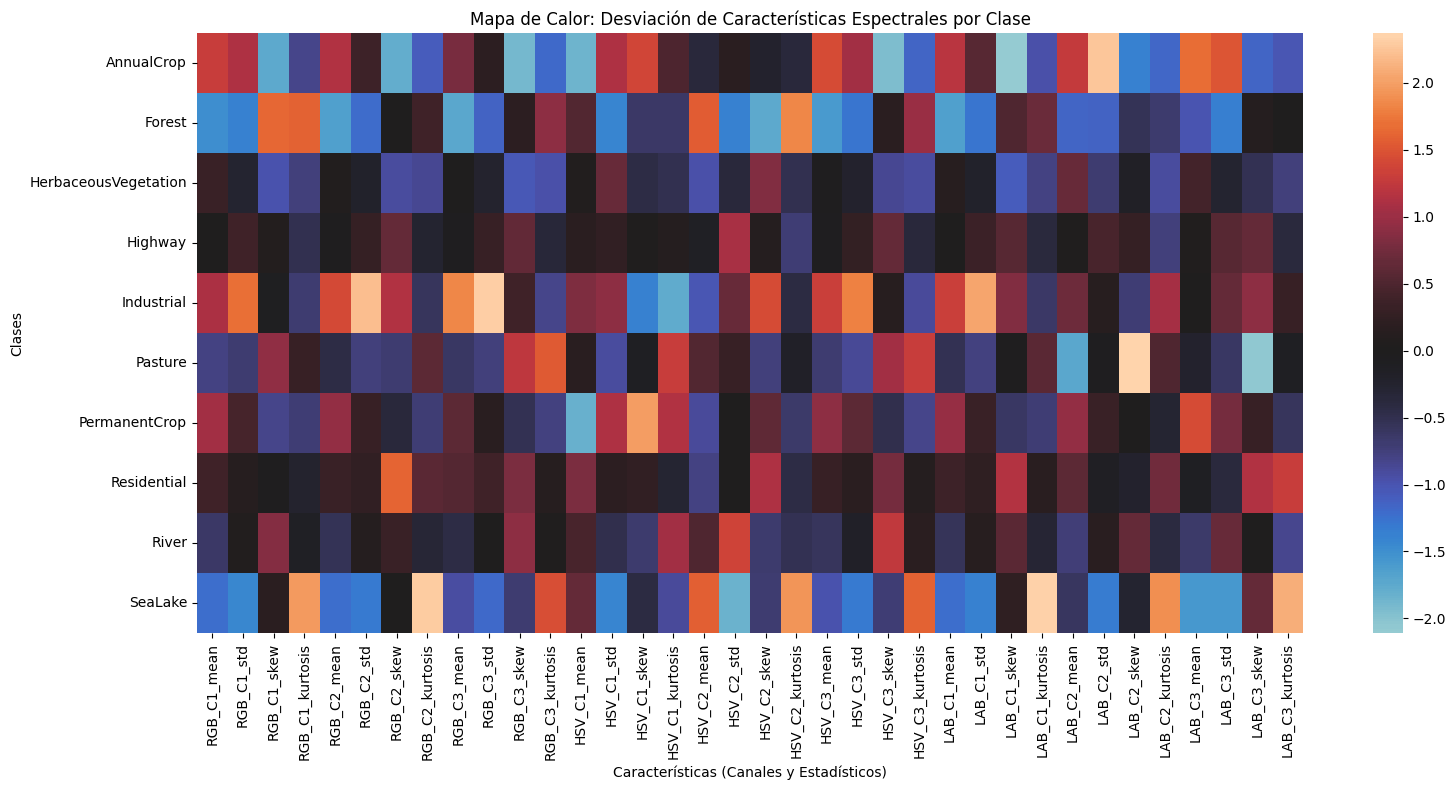

/tmp/ipykernel_896/2571164878.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='label_name', y='HSV_C1_mean', data=df_features, palette='viridis')


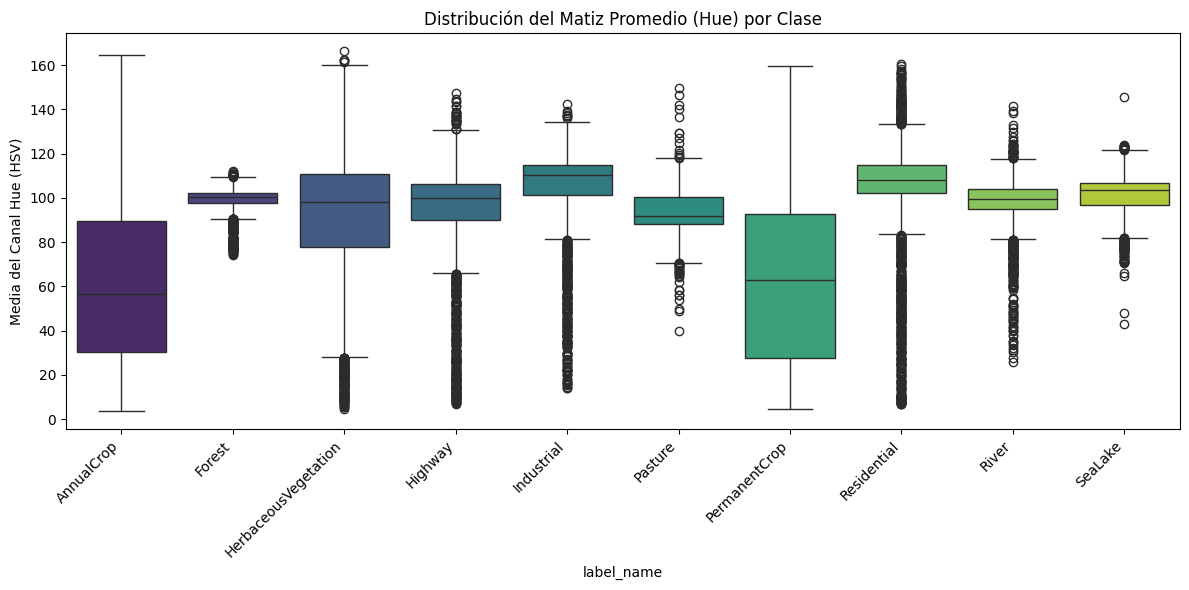


Top 5 características que más varían entre clases (mejor poder de separación):
RGB_C1_mean    1052.392119
HSV_C2_mean    1006.652812
LAB_C1_mean     521.992131
HSV_C3_mean     453.833833
RGB_C2_mean     396.795745
dtype: float64


In [ ]:
print("Resumen estadístico global (media y desviación de las características):")
global_stats = df_features.drop(columns=['label_idx', 'label_name']).describe().T
print(global_stats[['mean', 'std', 'min', 'max']])

class_centroids = df_features.drop(columns=['label_idx']).groupby('label_name').mean()

# Mapa de calor de las firmas espectrales
plt.figure(figsize=(16, 8))
class_centroids_scaled = (class_centroids - class_centroids.mean()) / class_centroids.std()

sns.heatmap(class_centroids_scaled, center=0, annot=False)
plt.title("Mapa de Calor: Desviación de Características Espectrales por Clase")
plt.xlabel("Características (Canales y Estadísticos)")
plt.ylabel("Clases")
plt.tight_layout()
plt.show()

# Boxplot para ver la varianza interna vs externa
# Comparamos el Matiz (Hue - HSV_C1_mean) entre las distintas clases
plt.figure(figsize=(12, 6))
sns.boxplot(x='label_name', y='HSV_C1_mean', data=df_features, palette='viridis')
plt.title("Distribución del Matiz Promedio (Hue) por Clase")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Media del Canal Hue (HSV)")
plt.tight_layout()
plt.show()

# Buscar características con mayor poder discriminativo
# Calculamos la varianza de los promedios entre clases para cada característica
variance_between_classes = class_centroids.var().sort_values(ascending=False)
print("\nTop 5 características que más varían entre clases (mejor poder de separación):")
print(variance_between_classes.head(5))